# Семинар 3. Одна задача оптимального управления — две численные постановки

Рассмотрим двойной интегратор
$$
\dot x_1=x_2,\qquad \dot x_2=u,
$$
с начальным условием
$$
x(0)=
\begin{pmatrix}
0\\
0
\end{pmatrix}.
$$

За время $T=2$ хотим приблизиться к состоянию
$$
x_{\mathrm{target}}=
\begin{pmatrix}
1\\
0
\end{pmatrix},
$$
при ограничении
$$
-1\le u(t)\le 1.
$$

Будем минимизировать
$$
J=
w_1(x_1(T)-1)^2+
w_2x_2(T)^2+
\lambda\int_0^T u^2(t)\,dt.
$$

После дискретизации одну и ту же задачу запишем двумя способами.

**A. Только управление — reduced formulation (single shooting).**  
Неизвестные — $u_0,\ldots,u_{N-1}$. Для каждого нового управления состояние вычисляется вперёд по динамике.

**B. Состояние и управление — direct transcription.**  
Неизвестные — $x_0,\ldots,x_N,u_0,\ldots,u_{N-1}$. Динамика записывается как система ограничений.

Это пока **не два способа дискретизации ОДУ**: сетка и формула перехода в обоих случаях будут одинаковыми. Мы сравниваем две постановки конечномерной задачи оптимизации.

Потом отдельно сравним две дискретизации динамики: Euler и точный переход.

Задача специально выбрана простой: после дискретизации она остаётся выпуклой. Поэтому обе постановки должны давать практически один и тот же минимум. Если результаты заметно различаются, сначала нужно искать причину в реализации или настройках solver'а.

## 0. Импорт

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from time import perf_counter
from scipy.optimize import minimize, NonlinearConstraint

## 1. Дискретная динамика

Разобьём $[0,T]$ на $N$ одинаковых интервалов:
$$
h=\frac{T}{N}.
$$

Управление считаем постоянным на каждом интервале:
$$
u(t)=u_k,\qquad t\in[t_k,t_{k+1}).
$$

Для двойного интегратора точный переход за один шаг имеет вид
$$
x_{1,k+1}
=
x_{1,k}+h x_{2,k}+\frac{h^2}{2}u_k,
$$
$$
x_{2,k+1}
=
x_{2,k}+hu_k.
$$

Перед запуском следующей ячейки:

1. сколько компонент у $x_k$;
2. сколько значений управления будет при $N=20$;
3. почему состояний будет $N+1$, а управлений — $N$?

**Ответы:** 1) У состояния две компоненты: положение и скорость. 2) При $N=20$ будет 20 значений управления. 3) Состояний 21: начальное и ещё по одному после каждого шага.

In [2]:
T = 2.0
N = 20
h = T / N

x0 = np.array([0.0, 0.0])
x_target = np.array([1.0, 0.0])

w1 = 100.0
w2 = 20.0
lam = 0.05


def step_exact(x, u, h):
    return np.array([
        x[0] + h * x[1] + 0.5 * h**2 * u,
        x[1] + h * u,
    ])

### Прямая симуляция

Если весь вектор управления уже известен, состояние можно последовательно вычислить от $t=0$ до $t=T$.

Обратите внимание на
```python
x = np.zeros((N + 1, 2))
```

Что означает каждая из двух размерностей этого массива?

**Ответ:** строки — моменты времени (всего $N+1$), столбцы — положение и скорость.

In [3]:
def simulate(u, step=step_exact):
    N_local = len(u)
    h_local = T / N_local

    x = np.zeros((N_local + 1, 2))
    x[0] = x0

    for k in range(N_local):
        x[k + 1] = step(x[k], u[k], h_local)

    return x

### До оптимизации

Проверим три простых управления:

- $u(t)=0$;
- $u(t)=1$;
- сначала $u=1$, затем $u=-1$.

До запуска попробуйте угадать, какое из них лучше всего приблизит систему к $(1,0)$.

**Предположение:** лучше всего сначала разогнаться, а потом затормозить. Так можно получить положение 1 и скорость 0.

In [4]:
u_zero = np.zeros(N)
u_one = np.ones(N)
u_switch = np.r_[np.ones(N // 2), -np.ones(N - N // 2)]

controls = {
    "u = 0": u_zero,
    "u = 1": u_one,
    "u = +1 / -1": u_switch,
}

for name, u in controls.items():
    x = simulate(u)
    print(f"{name:12s} -> x(T) = {x[-1]}")

u = 0        -> x(T) = [0. 0.]
u = 1        -> x(T) = [2. 2.]
u = +1 / -1  -> x(T) = [1.00000000e+00 2.77555756e-17]


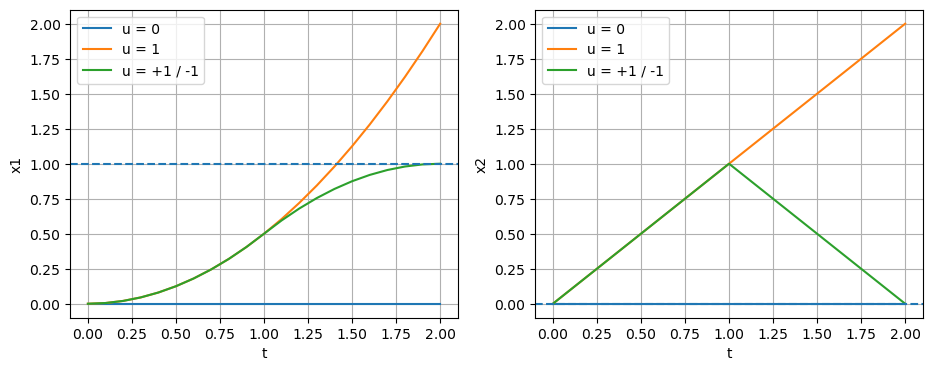

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

for name, u in controls.items():
    x = simulate(u)
    t_x = np.linspace(0, T, len(x))
    ax[0].plot(t_x, x[:, 0], label=name)
    ax[1].plot(t_x, x[:, 1], label=name)

ax[0].axhline(1, linestyle="--")
ax[0].set_xlabel("t")
ax[0].set_ylabel("x1")
ax[0].grid()
ax[0].legend()

ax[1].axhline(0, linestyle="--")
ax[1].set_xlabel("t")
ax[1].set_ylabel("x2")
ax[1].grid()
ax[1].legend()

plt.show()

## 2. Постановка A: только управление

Оптимизируем
$$
u=(u_0,\ldots,u_{N-1})\in[-1,1]^N.
$$

Для каждого нового $u$ функция `objective_u`:

1. вычисляет траекторию;
2. берёт конечное состояние;
3. считает штраф за ошибку в конечной точке;
4. добавляет стоимость управления.

Состояния $x_k$ здесь **не являются переменными оптимизатора**. Они однозначно восстанавливаются по $u$.

Такую постановку часто называют reduced formulation; в задачах ОУ близкий по смыслу термин — single shooting.

In [6]:
def objective_u(u):
    x = simulate(u)
    e = x[-1] - x_target

    terminal_cost = w1 * e[0]**2 + w2 * e[1]**2
    control_cost = lam * (T / len(u)) * np.sum(u**2)

    return terminal_cost + control_cost

### Два метода `scipy.optimize`

Ограничение $-1\le u_k\le1$ здесь задаётся через `bounds`.

Сравним:

- `L-BFGS-B`;
- `SLSQP`.

Перед запуском ответьте:

1. сколько здесь переменных оптимизации;
2. есть ли отдельные ограничения на динамику;
3. почему `L-BFGS-B`, который умеет работать с bounds, подходит к этой постановке?

Для более честного сравнения явно зададим достаточно строгие tolerances. Значение `success=True` само по себе ещё не гарантирует, что два solver'а нашли решения одинакового качества.

**Ответы:** 1) Переменных 20. 2) Отдельных ограничений на динамику нет, она уже учтена в `simulate`. 3) `L-BFGS-B` подходит, потому что нужны только границы для управления.

In [7]:
def solve_control_only(method):
    u0_guess = np.zeros(N)
    bounds_u = [(-1.0, 1.0)] * N

    options = {"maxiter": 1000}

    if method == "L-BFGS-B":
        options["ftol"] = 1e-12
    elif method == "SLSQP":
        options["ftol"] = 1e-10

    start = perf_counter()

    res = minimize(
        objective_u,
        u0_guess,
        method=method,
        bounds=bounds_u,
        options=options,
    )

    elapsed = perf_counter() - start
    return res, elapsed


control_only_results = {}

for method in ["L-BFGS-B", "SLSQP"]:
    res, elapsed = solve_control_only(method)
    control_only_results[method] = (res, elapsed)

    x = simulate(res.x)

    print(
        f"{method:10s}  "
        f"success={res.success}  "
        f"J={res.fun:.8f}  "
        f"nit={res.nit}  "
        f"nfev={res.nfev}  "
        f"time={elapsed:.3f}s  "
        f"x(T)={x[-1]}"
    )

L-BFGS-B    success=True  J=0.09001945  nit=23  nfev=630  time=0.056s  x(T)=[0.99749515 0.01244654]
SLSQP       success=True  J=0.09001945  nit=15  nfev=317  time=0.024s  x(T)=[0.99749512 0.01244648]


### Сравните решения

Если оба метода решили задачу с достаточной точностью, значения $J$ и найденные управления должны быть близкими.

Поскольку управление кусочно-постоянное, для его изображения удобно использовать `plt.stairs`.

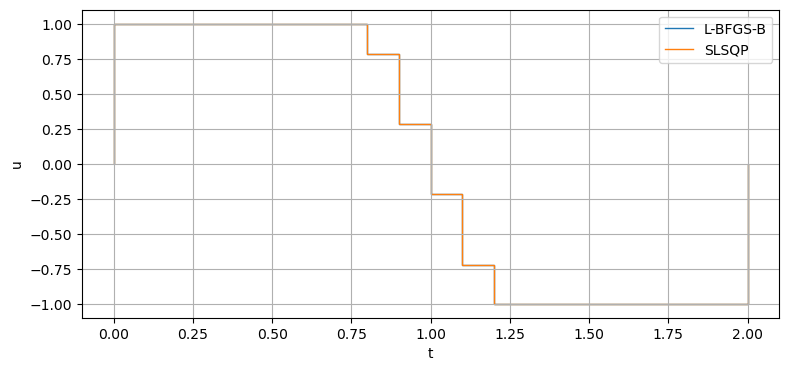

In [8]:
t_edges = np.linspace(0, T, N + 1)

plt.figure(figsize=(9, 4))

for method, (res, _) in control_only_results.items():
    plt.stairs(res.x, t_edges, label=method)

plt.xlabel("t")
plt.ylabel("u")
plt.ylim(-1.1, 1.1)
plt.grid()
plt.legend()
plt.show()

### Быстрая проверка

Ответьте:

1. насколько близки значения функционала;
2. насколько близки найденные управления;
3. какой метод сделал меньше итераций;
4. означает ли меньшее `nfev`, что метод обязательно лучше;
5. почему при сравнении solver'ов нужно смотреть не только на `success`, но и на значение $J$ и выполнение ограничений?

**Ответы:** 1) $J$ практически совпадает. 2) Управления тоже почти одинаковые. 3) В этом запуске меньше итераций сделал `SLSQP`. 4) Нет, `nfev` не учитывает всю работу алгоритма. 5) Нужно ещё проверить значение $J$ и ограничения, иначе решение может быть неточным.

## 3. Постановка B: состояния тоже становятся переменными

Теперь используем direct transcription. Неизвестным будет вектор
$$
z=
(x_0,x_1,\ldots,x_N,u_0,\ldots,u_{N-1}).
$$

Для $N=20$ переменных станет заметно больше.

Сначала посчитайте размерность $z$ самостоятельно. Затем сравните её с количеством равенств, которыми задаётся динамика.

**Ответ:** при $N=20$ получается 62 переменные, 42 равенства и 20 степеней свободы.

In [9]:
def pack(x, u):
    return np.concatenate([x.ravel(), u])


def unpack(z):
    nx = 2 * (N + 1)

    x = z[:nx].reshape(N + 1, 2)
    u = z[nx:]

    return x, u


n_z = 2 * (N + 1) + N
n_eq = 2 * (N + 1)  # x(0)=x0 и по 2 уравнения динамики на каждом шаге

print("Переменных:", n_z)
print("Равенств:", n_eq)
print("Степеней свободы после учёта равенств:", n_z - n_eq)

Переменных: 62
Равенств: 42
Степеней свободы после учёта равенств: 20


### Что стало с динамикой?

Раньше состояние автоматически вычислялось функцией `simulate`.

Теперь оптимизатор свободно меняет и $x$, и $u$. Поэтому отдельно потребуем
$$
x_0=x_{\mathrm{init}},
$$
а для каждого $k$
$$
x_{k+1}=F(x_k,u_k).
$$

Запишем эти равенства как
$$
c(z)=0.
$$

При $N=20$ получаем 62 переменные и 42 равенства. После их учёта остаётся 20 степеней свободы — столько же, сколько компонент управления в первой постановке.

То есть две постановки описывают одну и ту же дискретную задачу, просто по-разному организуют переменные и ограничения.

In [10]:
def dynamics_residual(z):
    x, u = unpack(z)

    residuals = [x[0] - x0]

    for k in range(N):
        residuals.append(
            x[k + 1] - step_exact(x[k], u[k], h)
        )

    return np.concatenate(residuals)

Функционал остаётся тем же. Разница только в том, откуда берётся состояние: теперь оно извлекается прямо из $z$.

In [11]:
def objective_z(z):
    x, u = unpack(z)

    e = x[-1] - x_target

    terminal_cost = w1 * e[0]**2 + w2 * e[1]**2
    control_cost = lam * h * np.sum(u**2)

    return terminal_cost + control_cost

### Начальное приближение

Возьмём $u=0$ и построим соответствующую ему траекторию. Это автоматически даст начальную точку, которая уже удовлетворяет динамике.

In [12]:
u_guess = np.zeros(N)
x_guess = simulate(u_guess)
z0 = pack(x_guess, u_guess)

print("Размер z0:", len(z0))
print("max |c(z0)| =", np.max(np.abs(dynamics_residual(z0))))

Размер z0: 62
max |c(z0)| = 0.0


### Ограничения на переменные

Для состояний пока bounds не задаём. Для последних $N$ компонент, то есть для управления, остаётся
$$
-1\le u_k\le1.
$$

In [13]:
bounds_z = (
    [(None, None)] * (2 * (N + 1))
    + [(-1.0, 1.0)] * N
)

### Решаем через `SLSQP`

Теперь одного `bounds` недостаточно: нужно ещё передать равенства $c(z)=0$.

In [14]:
eq_constraint = {
    "type": "eq",
    "fun": dynamics_residual,
}

start = perf_counter()

res_tr_slsqp = minimize(
    objective_z,
    z0,
    method="SLSQP",
    bounds=bounds_z,
    constraints=eq_constraint,
    options={
        "maxiter": 500,
        "ftol": 1e-10,
    },
)

time_tr_slsqp = perf_counter() - start

x_tr_slsqp, u_tr_slsqp = unpack(res_tr_slsqp.x)

print("success:", res_tr_slsqp.success)
print("J:", res_tr_slsqp.fun)
print("nit:", res_tr_slsqp.nit)
print("nfev:", res_tr_slsqp.nfev)
print("time:", time_tr_slsqp)
print("x(T):", x_tr_slsqp[-1])
print("max dynamic residual:",
      np.max(np.abs(dynamics_residual(res_tr_slsqp.x))))

success: True
J: 0.09001944769246185
nit: 22
nfev: 1387
time: 0.15036125400001765
x(T): [0.99749509 0.0124466 ]
max dynamic residual: 7.992495554276502e-13


### Ещё один solver: `trust-constr`

`L-BFGS-B` умеет работать с bounds, но не с общими равенствами вида $c(z)=0$. Поэтому для direct transcription сравним `SLSQP` с `trust-constr`.

В этой конкретной задаче ограничения динамики линейны, хотя мы передаём их через общий интерфейс `NonlinearConstraint`. Это сделано, чтобы тот же шаблон потом можно было использовать и для нелинейной динамики.

In [15]:
nonlinear_constraint = NonlinearConstraint(
    dynamics_residual,
    0.0,
    0.0,
)

start = perf_counter()

res_tr_trust = minimize(
    objective_z,
    z0,
    method="trust-constr",
    bounds=bounds_z,
    constraints=[nonlinear_constraint],
    options={
        "maxiter": 300,
        "gtol": 1e-8,
    },
)

time_tr_trust = perf_counter() - start

x_tr_trust, u_tr_trust = unpack(res_tr_trust.x)

print("success:", res_tr_trust.success)
print("J:", res_tr_trust.fun)
print("nit:", res_tr_trust.nit)
print("nfev:", res_tr_trust.nfev)
print("time:", time_tr_trust)
print("x(T):", x_tr_trust[-1])
print("max dynamic residual:",
      np.max(np.abs(dynamics_residual(res_tr_trust.x))))

success: True
J: 0.09002021505869952
nit: 125
nfev: 7308
time: 0.9627573159996246
x(T): [0.99749491 0.01244761]
max dynamic residual: 7.033262861000367e-14


## 4. Сводное сравнение

Соберём характеристики всех четырёх запусков:

- `success`;
- значение функционала;
- ошибку в конечной точке;
- расход управления;
- число итераций;
- `nfev` и `njev`;
- время;
- максимальную невязку динамики.

С `nfev` нужна осторожность. В reduced formulation один вызов `objective_u` включает полную симуляцию траектории. В direct transcription `objective_z` дешевле, зато solver отдельно вычисляет ограничения и их производные. Поэтому `nfev` между двумя постановками нельзя считать прямой мерой общей вычислительной работы.

Время тоже зависит от компьютера и конкретного запуска. Здесь оно нужно скорее для общей картины.

In [16]:
def control_effort(u):
    return h * np.sum(u**2)


def terminal_error(x):
    return np.linalg.norm(x[-1] - x_target)


rows = []

for method, (res, elapsed) in control_only_results.items():
    u = res.x
    x = simulate(u)

    z_check = pack(x, u)

    rows.append({
        "formulation": "control only",
        "method": method,
        "success": res.success,
        "n_variables": len(u),
        "J": res.fun,
        "terminal_error": terminal_error(x),
        "control_effort": control_effort(u),
        "nit": res.nit,
        "nfev": res.nfev,
        "njev": getattr(res, "njev", np.nan),
        "time_s": elapsed,
        "dyn_residual": np.max(np.abs(dynamics_residual(z_check))),
    })


for method, res, elapsed in [
    ("SLSQP", res_tr_slsqp, time_tr_slsqp),
    ("trust-constr", res_tr_trust, time_tr_trust),
]:
    x, u = unpack(res.x)

    rows.append({
        "formulation": "state + control",
        "method": method,
        "success": res.success,
        "n_variables": len(res.x),
        "J": res.fun,
        "terminal_error": terminal_error(x),
        "control_effort": control_effort(u),
        "nit": res.nit,
        "nfev": res.nfev,
        "njev": getattr(res, "njev", np.nan),
        "time_s": elapsed,
        "dyn_residual": np.max(np.abs(dynamics_residual(res.x))),
    })


comparison = pd.DataFrame(rows)
comparison

,formulation,method,success,n_variables,J,terminal_error,control_effort,nit,nfev,njev,time_s,dyn_residual
0,control only,L-BFGS-B,True,20,0.090019,0.012696,1.725874,23,630,30,0.055867,0.000000e+00
1,control only,SLSQP,True,20,0.090019,0.012696,1.725874,15,317,15,0.023762,0.000000e+00
2,state + control,SLSQP,True,62,0.090019,0.012696,1.725873,22,1387,22,0.150361,7.992496e-13
3,state + control,trust-constr,True,62,0.090020,0.012697,1.725876,125,7308,116,0.962757,7.033263e-14


### Сравним сами решения

Возьмём:

- `L-BFGS-B` для reduced formulation;
- `SLSQP` для direct transcription.

В нашей выпуклой задаче они должны привести практически к одной и той же траектории и одному управлению.

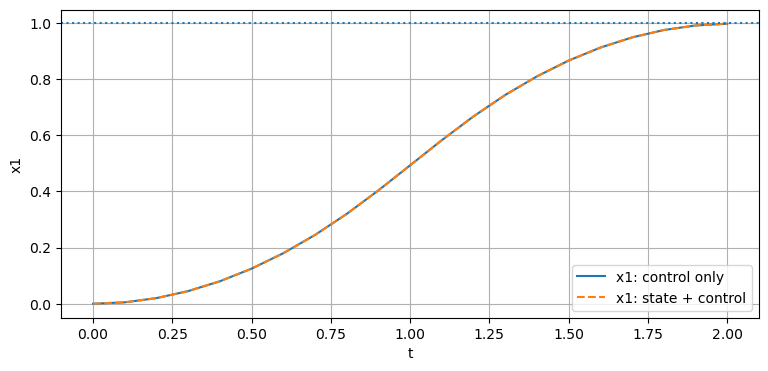

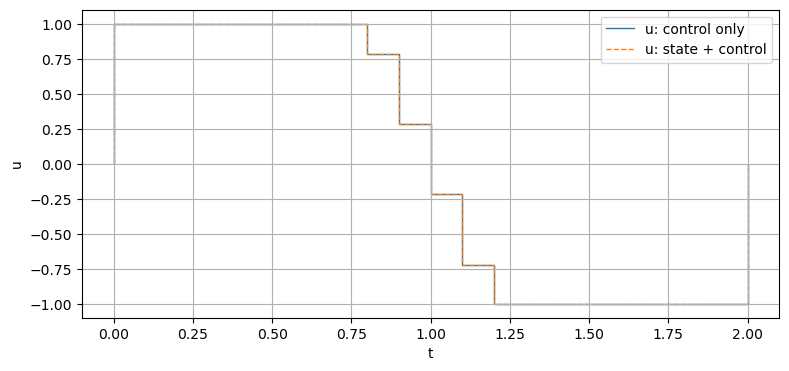

max |u_A - u_B| = 2.2472730415445952e-05
max |x_A - x_B| = 2.183417951107103e-06


In [17]:
res_a = control_only_results["L-BFGS-B"][0]
u_a = res_a.x
x_a = simulate(u_a)

u_b = u_tr_slsqp
x_b = x_tr_slsqp

t_x = np.linspace(0, T, N + 1)
t_edges = np.linspace(0, T, N + 1)

plt.figure(figsize=(9, 4))
plt.plot(t_x, x_a[:, 0], label="x1: control only")
plt.plot(t_x, x_b[:, 0], "--", label="x1: state + control")
plt.axhline(1, linestyle=":")
plt.xlabel("t")
plt.ylabel("x1")
plt.grid()
plt.legend()
plt.show()

plt.figure(figsize=(9, 4))
plt.stairs(u_a, t_edges, label="u: control only")
plt.stairs(u_b, t_edges, linestyle="--", label="u: state + control")
plt.xlabel("t")
plt.ylabel("u")
plt.ylim(-1.1, 1.1)
plt.grid()
plt.legend()
plt.show()

print("max |u_A - u_B| =", np.max(np.abs(u_a - u_b)))
print("max |x_A - x_B| =", np.max(np.abs(x_a - x_b)))

### Обсудите

1. Почему две постановки дают почти одно и то же решение?
2. Почему во второй постановке переменных больше, но после учёта равенств число степеней свободы совпадает с первой?
3. В какой постановке динамика выполняется автоматически?
4. В какой постановке динамика становится ограничением оптимизации?
5. Почему `L-BFGS-B` можно напрямую использовать в первой постановке, но не во второй?
6. Какая постановка будет удобнее, если появятся ограничения на состояние?
7. Можно ли по этой одной задаче сделать вывод, что одна постановка всегда быстрее другой?

**Ответы:**

1. Это одна и та же дискретная задача, поэтому минимум совпадает.
2. Во второй постановке есть лишние переменные состояния, но их определяют 42 равенства: остаётся 20 степеней свободы.
3. В reduced formulation динамику автоматически выполняет `simulate`.
4. В direct transcription динамика задаётся равенствами.
5. `L-BFGS-B` работает с bounds, но не с равенствами динамики.
6. Для ограничений на состояние удобнее direct transcription.
7. Нет, скорость зависит и от задачи, и от реализации.

## 5. Теперь сравним две дискретизации динамики

До этого формула перехода была одной и той же — менялась только постановка оптимизации.

Теперь вместо точного перехода возьмём Euler:
$$
x_{1,k+1}=x_{1,k}+h x_{2,k},
$$
$$
x_{2,k+1}=x_{2,k}+h u_k.
$$

Для двойного интегратора точный шаг известен, поэтому можно напрямую увидеть ошибку Euler.

Важно различать две ошибки:

- solver может неточно решить уже дискретизированную задачу;
- сама дискретная модель может неточно описывать исходную непрерывную систему.

Euler optimization success: True
J on Euler model: 0.09033293221240031
Same u, J on exact dynamics: 0.09005512081692375
Exact-model optimum J: 0.09001944768575748

Euler model x(T): [0.9974169  0.01219411]
Same u with exact dynamics x(T): [0.99802661 0.01219411]
Endpoint model error: 0.000609705322566434
max |u_Euler - u_exact| = 0.024147835751963886


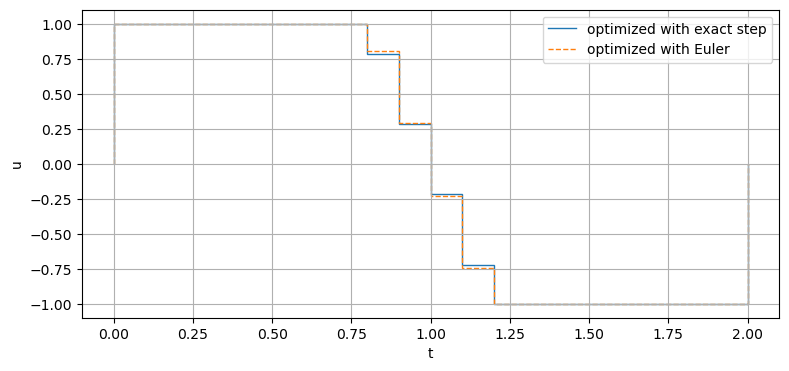

In [18]:
def step_euler(x, u, h):
    return np.array([
        x[0] + h * x[1],
        x[1] + h * u,
    ])


def objective_u_euler(u):
    x = simulate(u, step=step_euler)
    e = x[-1] - x_target

    return (
        w1 * e[0]**2
        + w2 * e[1]**2
        + lam * (T / len(u)) * np.sum(u**2)
    )


res_euler = minimize(
    objective_u_euler,
    np.zeros(N),
    method="L-BFGS-B",
    bounds=[(-1.0, 1.0)] * N,
    options={
        "maxiter": 1000,
        "ftol": 1e-12,
    },
)

u_euler = res_euler.x

x_euler_model = simulate(u_euler, step=step_euler)
x_euler_checked_exact = simulate(u_euler, step=step_exact)

print("Euler optimization success:", res_euler.success)
print("J on Euler model:", res_euler.fun)
print("Same u, J on exact dynamics:", objective_u(u_euler))
print("Exact-model optimum J:", res_a.fun)
print()
print("Euler model x(T):", x_euler_model[-1])
print("Same u with exact dynamics x(T):", x_euler_checked_exact[-1])
print(
    "Endpoint model error:",
    np.linalg.norm(x_euler_checked_exact[-1] - x_euler_model[-1])
)
print(
    "max |u_Euler - u_exact| =",
    np.max(np.abs(u_euler - u_a))
)

plt.figure(figsize=(9, 4))
plt.stairs(u_a, t_edges, label="optimized with exact step")
plt.stairs(u_euler, t_edges, linestyle="--", label="optimized with Euler")
plt.xlabel("t")
plt.ylabel("u")
plt.ylim(-1.1, 1.1)
plt.grid()
plt.legend()
plt.show()

Оптимизатор может очень хорошо решить **Euler-модель**, но управление, найденное для этой модели, всё равно стоит проверить на более точной динамике.

### В конце пары

Сформулируйте своими словами три разных сравнения:

1. reduced formulation против direct transcription;
2. разные методы `scipy.optimize` внутри выбранной постановки;
3. Euler против точного перехода.

Это три разных источника различий в численных результатах.

**Ответы:** 1) Reduced и direct отличаются выбором переменных и способом учёта динамики. 2) Solver'ы отличаются алгоритмом поиска минимума. 3) Euler и точный шаг отличаются способом вычисления состояния; Euler добавляет ошибку дискретизации.

# Домашняя работа — срок 2 недели

Продолжайте работу в этом notebook.

Перед первым заданием приведите функции к виду, в котором $N$ не приходится менять вручную в нескольких местах. Например, сделайте $N$ аргументом функций, которые решают задачу. То же самое пригодится позже для $\lambda$.

## 1. Сгущение сетки

Повторите расчёты для
$$
N=10,\quad20,\quad40,\quad80.
$$

Для каждого $N$ решите задачу:

- reduced formulation методом `L-BFGS-B`;
- direct transcription методом `SLSQP`.

Используйте те же tolerances, что и на семинаре.

Составьте таблицу:

`N`, `formulation`, `n_variables`, `J`, `terminal_error`, `control_effort`, `nit`, `nfev`, `time_s`.

Время одного запуска — шумная величина. Если компьютер позволяет, запустите каждый вариант 3 раза и запишите медианное время.

Постройте зависимости времени решения и $J$ от $N$.

Ответьте:

1. как растёт размерность обеих задач;
2. стабилизируются ли $J$ и управление при сгущении сетки;
3. какая постановка оказалась быстрее именно в этом эксперименте;
4. почему этот результат нельзя автоматически переносить на все задачи оптимального управления?

,N,formulation,n_variables,J,terminal_error,control_effort,nit,nfev,time_s
0,10,reduced,10,0.091454,0.014514,1.731700,35,561,0.034540
1,10,direct,32,0.091454,0.014513,1.731709,11,12,0.002599
2,20,reduced,20,0.090019,0.012696,1.725874,23,630,0.047526
3,20,direct,62,0.090019,0.012696,1.725873,22,23,0.011595
4,40,reduced,40,0.089715,0.012308,1.724277,46,2583,0.309671
5,40,direct,122,0.089715,0.012311,1.724246,29,31,0.076722
6,80,reduced,80,0.089642,0.012222,1.723785,33,3078,0.549211
7,80,direct,242,0.089642,0.012226,1.723745,48,50,1.023078


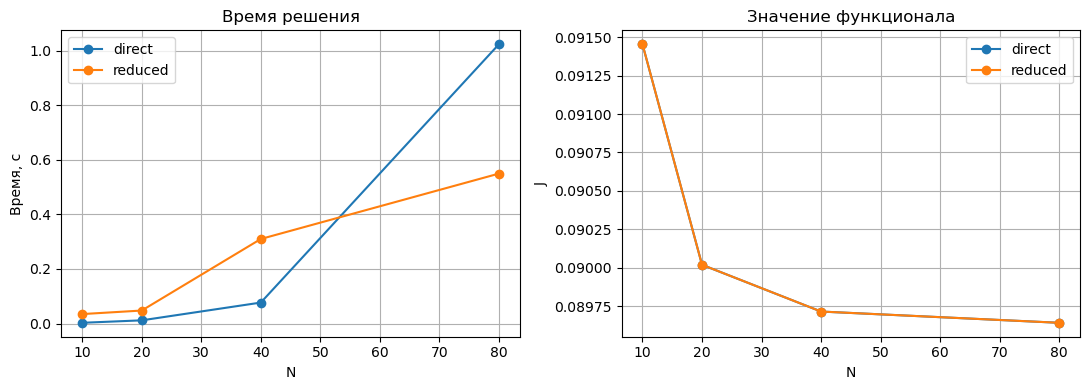

N=10: max разница управлений = 2.06e-05
N=10: быстрее direct
N=20: max разница управлений = 2.25e-05
N=20: быстрее direct
N=40: max разница управлений = 1.22e-04
N=40: быстрее direct
N=80: max разница управлений = 1.39e-04
N=80: быстрее reduced


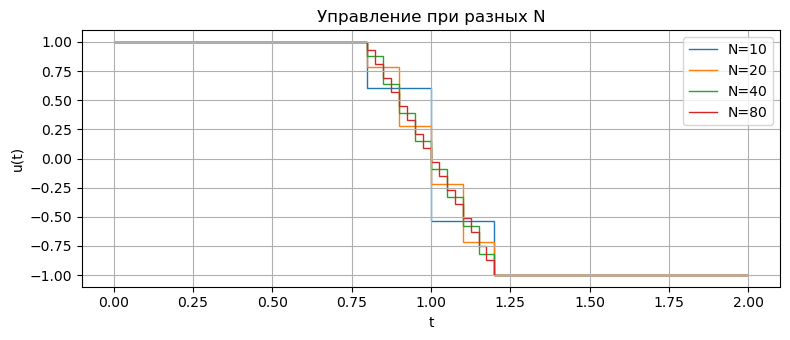

N=10: среднеквадратичное отличие от N=80 = 0.13004
N=20: среднеквадратичное отличие от N=80 = 0.06102
N=40: среднеквадратичное отличие от N=80 = 0.02703


In [19]:
# Общие функции для всех домашних заданий. N и lambda теперь аргументы.
pd.set_option("display.max_columns", None)
from scipy.optimize import LinearConstraint
from scipy.sparse import csr_matrix


def trajectory(u, scheme="exact"):
    n = len(u)
    dt = T / n
    x = np.zeros((n + 1, 2))
    for k in range(n):
        if scheme == "Euler":
            x[k + 1] = step_euler(x[k], u[k], dt)
        else:
            x[k + 1] = step_exact(x[k], u[k], dt)
    return x


def cost_u(u, a=0.05, scheme="exact"):
    x = trajectory(u, scheme)
    e = x[-1] - x_target
    return w1 * e[0]**2 + w2 * e[1]**2 + a * (T / len(u)) * np.sum(u**2)


def grad_u(u, a=0.05, scheme="exact"):
    n = len(u)
    dt = T / n
    e = trajectory(u, scheme)[-1] - x_target
    k = np.arange(n)
    p = dt * (T - (k + 0.5) * dt) if scheme == "exact" else dt * (T - (k + 1) * dt)
    return 2 * w1 * e[0] * p + 2 * w2 * e[1] * dt + 2 * a * dt * u


def solve_u(n, method="L-BFGS-B", a=0.05, scheme="exact", speed_limit=False):
    u0 = np.zeros(n)
    bounds = [(-1, 1)] * n
    options = {"maxiter": 1000}
    options["ftol"] = 1e-12 if method == "L-BFGS-B" else 1e-10
    if method == "Powell":
        options["xtol"] = 1e-8

    cons = []
    if speed_limit:
        # Сразу два неравенства: x2 <= 0.8 и x2 >= -0.8.
        def speed_ok(u):
            v = trajectory(u)[:, 1]
            return np.r_[0.8 - v, 0.8 + v]
        cons = [{"type": "ineq", "fun": speed_ok}]

    t = perf_counter()
    res = minimize(
        lambda u: cost_u(u, a, scheme), u0,
        method=method, bounds=bounds, constraints=cons,
        jac=(lambda u: grad_u(u, a, scheme)) if method == "SLSQP" else None,
        options=options,
    )
    return res, perf_counter() - t


def transcription_matrix(n):
    dt = T / n
    m = 2 * (n + 1)
    A = np.zeros((m, m + n))
    A[0, 0] = 1
    A[1, 1] = 1
    for k in range(n):
        i = 2 * (k + 1)
        A[i, i] = 1
        A[i, i - 2] = -1
        A[i, i - 1] = -dt
        A[i, m + k] = -0.5 * dt**2
        A[i + 1, i + 1] = 1
        A[i + 1, i - 1] = -1
        A[i + 1, m + k] = -dt
    return A


def solve_z(n, method="SLSQP", a=0.05, speed_limit=False):
    dt = T / n
    m = 2 * (n + 1)
    A = transcription_matrix(n)
    z0 = np.r_[trajectory(np.zeros(n)).ravel(), np.zeros(n)]

    bounds = [(None, None)] * m + [(-1, 1)] * n
    if speed_limit:
        for k in range(n + 1):
            bounds[2 * k + 1] = (-0.8, 0.8)

    def f(z):
        e = z[m - 2:m] - x_target
        return w1 * e[0]**2 + w2 * e[1]**2 + a * dt * np.sum(z[m:]**2)

    def grad(z):
        g = np.zeros(m + n)
        g[m - 2] = 2 * w1 * (z[m - 2] - 1)
        g[m - 1] = 2 * w2 * z[m - 1]
        g[m:] = 2 * a * dt * z[m:]
        return g

    t = perf_counter()
    if method == "SLSQP":
        res = minimize(f, z0, method="SLSQP", jac=grad, bounds=bounds,
                       constraints=[{"type": "eq", "fun": lambda z: A @ z,
                                     "jac": lambda z: A}],
                       options={"maxiter": 500, "ftol": 1e-10})
    else:
        # Динамика линейна, поэтому здесь её можно задать через LinearConstraint.
        H = np.zeros((m + n, m + n))
        H[m - 2, m - 2] = 2 * w1
        H[m - 1, m - 1] = 2 * w2
        H[m:, m:] = np.eye(n) * (2 * a * dt)
        res = minimize(f, z0, method="trust-constr", jac=grad,
                       hess=lambda z: csr_matrix(H), bounds=bounds,
                       constraints=[LinearConstraint(csr_matrix(A), 0, 0)],
                       options={"maxiter": 300, "gtol": 1e-8})
    return res, perf_counter() - t, A


def result_row(n, form, method, res, elapsed):
    if form == "reduced":
        u = res.x
        x = trajectory(u)
    else:
        m = 2 * (n + 1)
        x = res.x[:m].reshape(n + 1, 2)
        u = res.x[m:]
    return {
        "N": n, "formulation": form, "n_variables": len(res.x),
        "J": res.fun, "terminal_error": np.linalg.norm(x[-1] - x_target),
        "control_effort": (T / n) * np.sum(u**2),
        "nit": res.nit, "nfev": res.nfev, "time_s": elapsed,
    }


# Три запуска, чтобы взять медиану времени.
rows1 = []
solutions1 = {}
for n in [10, 20, 40, 80]:
    for form, method in [("reduced", "L-BFGS-B"), ("direct", "SLSQP")]:
        runs = [solve_u(n, method) if form == "reduced" else solve_z(n, method)
                for _ in range(3)]
        res = runs[-1][0]
        elapsed = float(np.median([r[1] for r in runs]))
        assert res.success, (n, form, res.message)
        if form == "direct":
            assert np.max(np.abs(runs[-1][2] @ res.x)) < 1e-6
        solutions1[(n, form)] = res
        rows1.append(result_row(n, form, method, res, elapsed))

table1 = pd.DataFrame(rows1)
display(table1.round(7))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for form, group in table1.groupby("formulation"):
    ax[0].plot(group.N, group.time_s, "o-", label=form)
    ax[1].plot(group.N, group.J, "o-", label=form)
ax[0].set(xlabel="N", ylabel="Время, с", title="Время решения")
ax[1].set(xlabel="N", ylabel="J", title="Значение функционала")
for a1 in ax:
    a1.grid(True)
    a1.legend()
plt.tight_layout()
plt.show()

for n in [10, 20, 40, 80]:
    a = solutions1[(n, "reduced")].x
    b = solutions1[(n, "direct")].x[2 * (n + 1):]
    print(f"N={n}: max разница управлений = {np.max(np.abs(a - b)):.2e}")
    subset = table1[table1.N == n].set_index("formulation")
    print(f"N={n}: быстрее {subset.time_s.idxmin()}")


# Проверим, что форма управления тоже перестаёт заметно меняться с ростом N.
plt.figure(figsize=(8, 3.5))
for n in [10, 20, 40, 80]:
    u = solutions1[(n, "reduced")].x
    plt.stairs(u, np.linspace(0, T, n + 1), baseline=None, label=f"N={n}")
plt.xlabel("t")
plt.ylabel("u(t)")
plt.title("Управление при разных N")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

# Сравниваем управления на общей временной сетке.
t_check = (np.arange(2000) + 0.5) * T / 2000
u_ref = solutions1[(80, "reduced")].x[np.minimum((t_check * 80 / T).astype(int), 79)]
for n in [10, 20, 40]:
    u = solutions1[(n, "reduced")].x[np.minimum((t_check * n / T).astype(int), n - 1)]
    print(f"N={n}: среднеквадратичное отличие от N=80 = {np.sqrt(np.mean((u-u_ref)**2)):.5f}")


**Ответы к заданию 1:**

1. В reduced formulation переменных $N$, а в direct transcription — $3N+2$.
2. Да, $J$ приближается к постоянному значению, а управление почти перестаёт меняться. Это видно на графиках и по сравнению с сеткой $N=80$.
3. На моём компьютере direct transcription была быстрее при $N=10,20,40$, а при $N=80$ быстрее оказалась reduced formulation. Это видно в таблице времени. При повторном запуске цифры могут немного меняться.
4. Скорость зависит не только от постановки, но и от метода, производных, размера задачи и компьютера. Поэтому общего победителя нет.


## 2. Сравнение solver'ов

Для $N=20$ сравните:

### Reduced formulation

- `L-BFGS-B`;
- `SLSQP`;
- `Powell`.

### Direct transcription

- `SLSQP`;
- `trust-constr`.

Для каждого запуска сохраните:

`success`, `J`, `nit`, `nfev`, `time_s`.

Кроме этого, посчитайте относительный разрыв по функционалу относительно лучшего найденного значения:
$$
\mathrm{gap}
=
\frac{J-J_{\min}}{|J_{\min}|}.
$$

`Powell` здесь специально включён как метод без использования градиента. Не удивляйтесь, если `success=True` у него не означает такое же качество решения, как у других методов.

Сделайте таблицу и короткий вывод. Не выбирайте «лучший solver вообще» — вывод относится только к этой задаче, этим tolerances и этой реализации.

In [20]:
# Сравнение методов при N=20.
rows2 = []
solvers2 = {}
for form, methods in [("reduced", ["L-BFGS-B", "SLSQP", "Powell"]),
                      ("direct", ["SLSQP", "trust-constr"])]:
    for method in methods:
        result = solve_u(20, method) if form == "reduced" else solve_z(20, method)
        res, elapsed = result[:2]
        solvers2[(form, method)] = res
        rows2.append({"formulation": form, "solver": method,
                      "success": res.success, "J": res.fun,
                      "nit": res.nit, "nfev": res.nfev, "time_s": elapsed,
                      "dyn_residual": 0 if form == "reduced"
                        else np.max(np.abs(result[2] @ res.x))})

table2 = pd.DataFrame(rows2)
J_min = table2.J.min()
table2["gap"] = (table2.J - J_min) / abs(J_min)
display(table2.round(9))
print("Лучшее найденное J =", round(J_min, 9))


,formulation,solver,success,J,nit,nfev,time_s,dyn_residual,gap
0,reduced,L-BFGS-B,True,0.090019,23,630,0.049667,0.0,0.000000
1,reduced,SLSQP,True,0.090019,15,17,0.005697,0.0,0.000000
2,reduced,Powell,True,0.121329,15,11473,0.841657,0.0,0.347806
3,direct,SLSQP,True,0.090019,22,23,0.010262,0.0,0.000000
4,direct,trust-constr,True,0.090024,25,17,0.078290,0.0,0.000048


Лучшее найденное J = 0.090019448


**Вывод:** методы с градиентом дали практически одинаковый результат. В этом запуске `Powell` работал дольше и нашёл заметно худшее значение $J$, хотя сообщил об успехе. `success=True` ещё не означает, что качество у всех одинаковое: надо смотреть $J$, `gap` и ограничения.

## 3. Euler против точного шага

Для
$$
N=10,\quad20,\quad40,\quad80
$$
решите reduced formulation дважды:

1. с `step_euler`;
2. с `step_exact`.

Для управления, найденного на Euler-модели, обязательно сделайте проверку на точной динамике.

Для каждого $N$ сохраните:

- $J$ на модели, на которой шла оптимизация;
- конечное состояние в этой модели;
- конечное состояние того же управления при точной динамике;
- норму разности этих конечных состояний;
- разность между оптимальными управлениями Euler и exact.

Постройте ошибку как функцию $N$.

Ответьте:

1. уменьшается ли ошибка при сгущении сетки;
2. чем эта ошибка отличается от ошибки, связанной с неточной остановкой optimizer'а?

,N,J_Euler_model,J_Euler_on_exact,J_exact_opt,xT_Euler,xT_checked_exact,endpoint_difference,max_u_difference
0,10,0.092284,0.091629,0.091454,"[0.996929, 0.013734]","[0.998302, 0.013734]",0.001373,0.042747
1,20,0.090333,0.090055,0.090019,"[0.997417, 0.012194]","[0.998027, 0.012194]",0.000610,0.024148
2,40,0.089862,0.089724,0.089715,"[0.997534, 0.011945]","[0.997833, 0.011945]",0.000299,0.013050
3,80,0.089714,0.089644,0.089642,"[0.997572, 0.011914]","[0.997721, 0.011914]",0.000149,0.006546


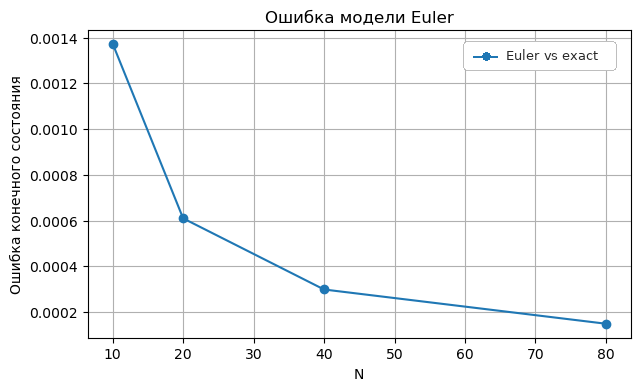

In [21]:
rows3 = []
for n in [10, 20, 40, 80]:
    re, _ = solve_u(n, scheme="Euler")
    rx, _ = solve_u(n, scheme="exact")
    ue = re.x
    xe = trajectory(ue, "Euler")
    xe_checked = trajectory(ue, "exact")
    rows3.append({
        "N": n,
        "J_Euler_model": re.fun,
        "J_Euler_on_exact": cost_u(ue),
        "J_exact_opt": rx.fun,
        "xT_Euler": np.round(xe[-1], 6),
        "xT_checked_exact": np.round(xe_checked[-1], 6),
        "endpoint_difference": np.linalg.norm(xe[-1] - xe_checked[-1]),
        "max_u_difference": np.max(np.abs(ue - rx.x)),
    })
    assert re.success and rx.success

table3 = pd.DataFrame(rows3)
display(table3)

plt.figure(figsize=(7, 4))
plt.plot(table3.N, table3.endpoint_difference, "o-", label="Euler vs exact")
plt.xlabel("N")
plt.ylabel("Ошибка конечного состояния")
plt.title("Ошибка модели Euler")
plt.grid(True)
plt.legend()
plt.show()


**Ответы к заданию 3:** 1) Да, при увеличении $N$ ошибка Euler уменьшается. 2) Ошибка дискретизации появляется из-за приближённого шага по времени. Ошибка оптимизатора возникает, если он не до конца решил уже дискретную задачу. Даже очень точная оптимизация сама по себе не исправляет ошибку Euler.

## 4. Ограничение на состояние

Добавим
$$
|x_2(t)|\le0.8.
$$

Решите задачу двумя способами.

### A. Reduced formulation

Состояние не является переменной оптимизации. Поэтому ограничение нужно вычислять через `simulate(u)` и передавать в `SLSQP` как inequality constraint.

### B. Direct transcription

Компоненты $x_{2,k}$ уже входят в $z$. Здесь ограничение можно задать непосредственно как bounds на соответствующие компоненты состояния.

Сравните:

- объём и структуру кода;
- размерность;
- время;
- найденные $u(t)$ и $x_2(t)$;
- максимальное нарушение ограничения.

После этого ответьте: какая постановка оказалась удобнее именно после появления ограничения на состояние?

Это один из главных практических аргументов в пользу direct transcription: ограничения на состояния в нём обычно задаются естественнее.

,formulation,n_variables,J,time_s,max_violation,max_dyn_residual
0,reduced,20,0.118795,0.031717,0,0.0
1,direct,62,0.118795,0.014906,0,0.0


max |u_A - u_B|: 1.5543122344752192e-15
max |x2_A - x2_B|: 2.220446049250313e-16


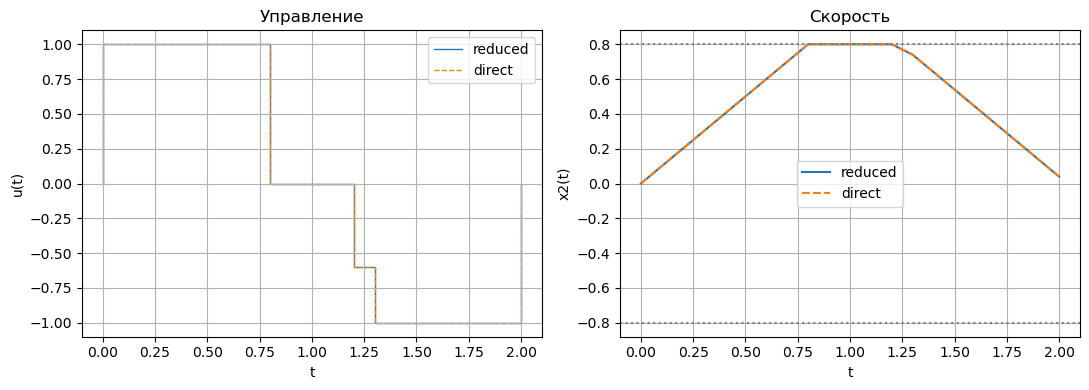

In [22]:
n = 20
ra, ta = solve_u(n, method="SLSQP", speed_limit=True)
rb, tb, A = solve_z(n, method="SLSQP", speed_limit=True)
assert ra.success and rb.success, (ra.message, rb.message)

ua, xa = ra.x, trajectory(ra.x)
xb = rb.x[:2 * (n + 1)].reshape(n + 1, 2)
ub = rb.x[2 * (n + 1):]

limit_a = max(0, np.max(np.abs(xa[:, 1])) - 0.8)
limit_b = max(0, np.max(np.abs(xb[:, 1])) - 0.8)

table4 = pd.DataFrame([
    {"formulation": "reduced", "n_variables": n, "J": ra.fun,
     "time_s": ta, "max_violation": limit_a,
     "max_dyn_residual": np.max(np.abs(A @ np.r_[xa.ravel(), ua]))},
    {"formulation": "direct", "n_variables": 3 * n + 2, "J": rb.fun,
     "time_s": tb, "max_violation": limit_b,
     "max_dyn_residual": np.max(np.abs(A @ rb.x))},
])
display(table4.round(9))
print("max |u_A - u_B|:", np.max(np.abs(ua - ub)))
print("max |x2_A - x2_B|:", np.max(np.abs(xa[:, 1] - xb[:, 1])))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
t = np.linspace(0, T, n + 1)
ax[0].stairs(ua, t, label="reduced")
ax[0].stairs(ub, t, linestyle="--", label="direct")
ax[0].set(xlabel="t", ylabel="u(t)", title="Управление")
ax[1].plot(t, xa[:, 1], label="reduced")
ax[1].plot(t, xb[:, 1], "--", label="direct")
ax[1].axhline(0.8, color="gray", linestyle=":")
ax[1].axhline(-0.8, color="gray", linestyle=":")
ax[1].set(xlabel="t", ylabel="x2(t)", title="Скорость")
for p in ax:
    p.grid(True)
    p.legend()
plt.tight_layout()
plt.show()


**Ответ:** оба способа дали практически одинаковые управление и скорость при выполненном ограничении. В reduced formulation достаточно $N$ переменных, но нужно отдельно считать ограничения через траекторию. В direct transcription переменных больше и нужно задать уравнения динамики, зато ограничение скорости записывается сразу в `bounds`. Поэтому с ограничениями на состояние мне удобнее direct transcription. Время и максимальные нарушения приведены в таблице.

## 5. Влияние веса управления

Возьмите
$$
\lambda=
10^{-3},\quad10^{-2},\quad10^{-1},\quad1.
$$

Для каждого $\lambda$ решите задачу в обеих постановках.

Посчитайте:

- terminal error;
- control effort;
- $J$.

Постройте график
$$
\text{terminal error}
\quad\text{против}\quad
\text{control effort}.
$$

На одном рисунке отметьте результаты обеих постановок.

Если реализации и tolerances подобраны корректно, соответствующие точки двух постановок должны лежать почти друг на друге. Если этого не происходит, проверьте `success`, невязку динамики и настройки solver'а.

,lambda,formulation,terminal_error,control_effort,J,dyn_residual,time_s
0,0.001,reduced,0.000910,1.959450,0.001979,0.0,0.245668
1,0.001,direct,0.000910,1.959454,0.001979,0.0,0.014962
2,0.010,reduced,0.004630,1.841520,0.018910,0.0,0.082144
3,0.010,direct,0.004630,1.841520,0.018910,0.0,0.011944
4,0.100,reduced,0.019407,1.658184,0.174529,0.0,0.050112
5,0.100,direct,0.019407,1.658186,0.174529,0.0,0.009014
6,1.000,reduced,0.088612,1.261861,1.445207,0.0,0.029814
7,1.000,direct,0.088612,1.261860,1.445207,0.0,0.006871


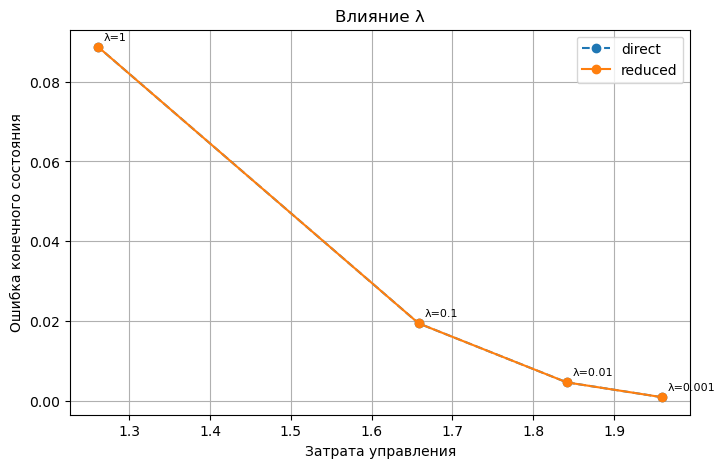

In [23]:
rows5 = []
for a in [1e-3, 1e-2, 1e-1, 1.0]:
    for form in ["reduced", "direct"]:
        if form == "reduced":
            res, elapsed = solve_u(20, a=a)
            u = res.x
            x = trajectory(u)
            dyn_res = 0.0
        else:
            res, elapsed, A = solve_z(20, a=a)
            x = res.x[:42].reshape(21, 2)
            u = res.x[42:]
            dyn_res = np.max(np.abs(A @ res.x))
        assert res.success, (a, form, res.message)
        rows5.append({"lambda": a, "formulation": form,
                      "terminal_error": np.linalg.norm(x[-1] - x_target),
                      "control_effort": (T / 20) * np.sum(u**2),
                      "J": res.fun, "dyn_residual": dyn_res,
                      "time_s": elapsed})

table5 = pd.DataFrame(rows5)
display(table5.round(8))

plt.figure(figsize=(8, 5))
for form, group in table5.groupby("formulation"):
    plt.plot(group.control_effort, group.terminal_error, "o-" if form == "reduced" else "o--", label=form)
    if form == "reduced":
        for _, r in group.iterrows():
            plt.annotate(f"λ={r['lambda']:g}", (r.control_effort, r.terminal_error),
                     xytext=(4, 5), textcoords="offset points", fontsize=8)
plt.xlabel("Затрата управления")
plt.ylabel("Ошибка конечного состояния")
plt.title("Влияние λ")
plt.legend()
plt.grid(True)
plt.show()


**Вывод:** когда $\lambda$ растёт, управление становится слабее, зато попасть точно в цель труднее. При маленьком $\lambda$ ошибка конечного состояния меньше, но расход управления выше. Результаты reduced и direct почти совпадают.

## Итог

В конце напишите **10–15 предложений**.

Нужны ответы на вопросы:

- чем reduced formulation отличается от direct transcription;
- почему в этой задаче они должны приводить к одному и тому же минимуму;
- что происходит с вычислительной стоимостью при росте $N$;
- как различались методы `scipy.optimize`;
- почему `success=True` недостаточно для сравнения качества решений;
- чем ошибка дискретизации отличается от ошибки optimizer'а;
- что изменилось после появления ограничения на состояние;
- когда вы бы выбрали reduced formulation, а когда direct transcription.

Не делайте вывод «метод X всегда быстрее метода Y» по одному примеру. В наших экспериментах SciPy использует в основном универсальные алгоритмы и численные производные; специализированные sparse-солверы для больших задач direct transcription могут вести себя совсем иначе.

## Перед сдачей

- выполните `Restart Kernel → Run All`;
- не вписывайте численные результаты вручную;
- таблицы должны собираться из результатов расчётов;
- подпишите оси и легенды;
- повторяющийся код вынесите в функции.

### Мой итог

В reduced formulation мы ищем только управление. В direct transcription ищем ещё и все состояния. Динамика в первом случае учитывается через симуляцию, а во втором — через равенства. Обе постановки описывают одну задачу, поэтому должны дать один минимум. При увеличении $N$ переменных становится больше и расчёт обычно дорожает. Зато значение $J$ стабилизируется при сгущении сетки. Методы `L-BFGS-B` и `SLSQP` дали близкие решения. `Powell` работает без градиента, поэтому его результат надо сравнивать особенно внимательно. Надпись `success=True` не гарантирует ни самый маленький $J$, ни точное выполнение всех ограничений. Ошибка Euler возникает из-за приближённой модели динамики. Ошибка оптимизатора — из-за неточного решения уже готовой дискретной задачи. После ограничения скорости в direct transcription оказалось проще задать bounds на состояния. Для небольшой задачи без ограничений на состояние я бы выбрал reduced formulation, а для задачи со многими ограничениями на состояния — direct transcription.